# ДДЗ-3. DLG: восстановление картинки по одному градиенту (CPU)

**Суть работы:** весь раздел 2 учит нас вычислять градиенты. Здесь мы посмотрим на них с обратной стороны — какую секретную информацию о данных они способны раскрыть сами по себе. 

### 🛡️ Сценарий атаки: Разрушение приватности во Federated Learning
В концепции федеративного обучения (Federated Learning) клиенты (например, больницы или смартфоны) обучают общую модель локально на своих устройствах. Чтобы защитить приватность, они отправляют на центральный сервер не сами сырые данные, а только получившиеся градиенты по весам. 

Метод **DLG** (*Deep Leakage from Gradients, Zhu–Liu–Han, 2019*) доказывает, что такая защита уязвима: даже по одному градиенту небольшой сети сервер может **восстановить** исходную тренировочную картинку практически со стопроцентной точностью.

---

### 🧮 Математическая постановка задачи
Модель обучается автоматически в первой ячейке ноутбука (используется тот же классификатор, что и в ДДЗ-1, самостоятельно обучать его не требуется). Дальнейший процесс представляет собой чисто численную оптимизацию. 

Сервер перехватывает истинный градиент $g$ и пытается подобрать такой фейковый вход $\hat{x}$ (а позже — и метку $y$), чтобы градиент от этой фейковой картинки максимально совпал с перехваченным:

$$\min_{\hat{x}} \; \sum_{\text{слои}} \frac{\left\| \nabla_{W} \mathrm{CE}(f(\hat{x}), y) - g_W \right\|^2}{\|g_W\|^2}$$

> 🔄 **Важно:** Здесь применяется механизм **двойного автодифференцирования** (прямое продолжение ПЗ-8). Градиент по весам $\nabla_W \mathrm{CE}$ сам напрямую зависит от подбираемого входа $\hat{x}$, и PyTorch будет брать производную уже от самого этого градиента. Подробнее этот процесс разобран в Разделе 1.

---

### 🗺️ План выполнения лабораторной работы
Номер шага строго соответствует номеру раздела в ноутбуке:

*   **Раздел 0: Подготовка** — Модель обучена, сервер перехватывает градиент от одной секретной цифры.
*   **Раздел 1: Шаг 1 (Основной)** — Восстановление изображения по градиенту при условии, что истинная метка класса нам известна.
*   **Раздел 2: Шаг 2 (★)** — Метка класса неизвестна: мы последовательно перебираем 10 кандидатов и вычисляем истинный класс из того же градиента.
*   **Раздел 3: Шаг 3 (★)** — Анализ батча: клиент отправляет усредненный градиент пакета из 4 картинок. Увидим в цифрах, как усреднение глушит утечку данных.
*   **Раздел 4: Шаг 4 (★★)** — Защита данных: добавление шума в градиент. Выясним эмпирически, насколько мала «рабочая» величина $\sigma$ шума и какова её цена для качества честного обучения.

---

### 📝 Правила сдачи и контроля
Прогоните ноутбук последовательно сверху вниз, заполняя блоки, отмеченные тегом `✍️ ДЕЛАЙТЕ`. 

⚠️ **Важное требование:** Встроенные блоки самопроверки жестко завязаны на конкретные переменные. Ни в коем случае не переименовывайте и не удаляйте переменные:
`net`, `x0`, `y0`, `gt`, `err`, `lab_losses`, `qlab`, `err_b4`, `err_noise`.

*Ориентировочное время полного выполнения кода: ~30 секунд на CPU.*


In [1]:
# Модель-жертва: маленький MLP на цифрах sklearn (как в ДДЗ-1)
import sys, time, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sys.stdout.reconfigure(encoding='utf-8', errors='replace')
torch.manual_seed(0)

dd = load_digits()
X, Y = dd.data / 16.0, dd.target
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.25,
                                      random_state=42, stratify=Y)
Xtr = torch.from_numpy(Xtr).float()
Xte = torch.from_numpy(Xte).float()
Ytr = torch.from_numpy(Ytr).long()
Yte = torch.from_numpy(Yte).long()

torch.manual_seed(0)
net32 = nn.Sequential(nn.Linear(64, 64), nn.ReLU(),
                      nn.Linear(64, 32), nn.ReLU(),
                      nn.Linear(32, 10))
opt = torch.optim.Adam(net32.parameters(), lr=1e-3)
t0 = time.perf_counter()
for ep in range(40):
    perm = torch.randperm(len(Xtr))
    for b in range(0, len(Xtr), 128):
        idx = perm[b:b + 128]
        opt.zero_grad()
        F.cross_entropy(net32(Xtr[idx]), Ytr[idx]).backward()
        opt.step()
with torch.no_grad():
    acc = float((net32(Xte).argmax(1) == Yte).float().mean())
print(f'модель обучена за {time.perf_counter()-t0:.1f}s | точность {acc:.4f}')

модель обучена за 1.0s | точность 0.9689


## Раздел 0. Перехват: сервер получает только градиенты

### 🎬 Сценарий атаки
Клиент (владелец секретного числа `x0`) делает один шаг локального обучения:
1. Вычисляет градиент функции потерь по всем весам.
2. Отправляет серверу **только этот градиент** — 6 векторов (по одному на каждый слой весов). 

> **Важно:** Ни выходы модели, ни исходная картинка не передаются. Внешне это выглядит так, будто данные вообще не покидали устройство клиента. Именно эту посылку и перехватывает злоумышленник.

---

### 🔍 Что известно атакующему?
* 🏗️ **Архитектура** нейросети.
* ⚖️ **Текущие веса** той же сети (базовое предположение сценария).
* 🎯 **Перехваченный градиент** (`gt`).

В коде ниже за этот этап отвечает функция `client_step` — внутри нее отрабатывает обычный `torch.autograd.grad` без каких-либо трюков и модификаций.

---

### ⚙️ Технический нюанс: точность данных
Для успешного проведения атаки модель принудительно переведена в формат **`float64` (double)**. 

* **Почему это необходимо?** Алгоритм подбирает входные данные с экстремально высокой точностью. Стандартного формата `float32` здесь просто не хватает (наглядные примеры в цифрах будут показаны чуть ниже).


секрет: цифра 0 (пример #161)
перехвачено градиентов: 6 | формы: [(64, 64), (64,)] , …
|g| слоёв: [0.0309, 0.0086, 0.0362, 0.0041, 0.063, 0.0038]


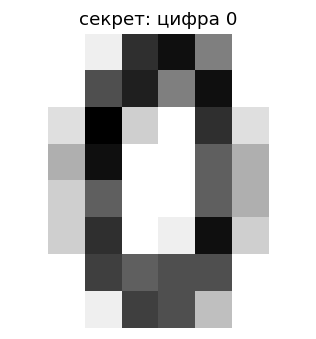

In [1]:
# секретная цифра + перехват градиента
net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(),
                    nn.Linear(64, 32), nn.ReLU(),
                    nn.Linear(32, 10)).double()      # атака в double
net.load_state_dict(net32.state_dict())
PKEYS = list(net.parameters())

SECRET_ID = 161                                   # фиксированный секрет
x0 = Xte[SECRET_ID:SECRET_ID + 1].clone().double()   # (1, 64) — секрет клиента
y0 = torch.tensor([int(Yte[SECRET_ID])])
print(f'секрет: цифра {int(y0)} (пример #{SECRET_ID})')


def client_step(xb, yb):
    """клиент: ОДИН шаг локального обучения, наружу идут ТОЛЬКО градиенты"""
    loss = F.cross_entropy(net(xb), yb)
    return torch.autograd.grad(loss, PKEYS)      # (без create_graph!)


gt = client_step(x0, y0)
print('перехвачено градиентов:', len(gt), '| формы:',
      [tuple(g.shape) for g in gt[:2]], ', …')
print('|g| слоёв:', [round(float(v), 4) for v in
                     [g.norm() for g in gt]])

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(x0[0].view(8, 8).numpy(), cmap='gray_r')
ax.set_title(f'секрет: цифра {int(y0)}')
ax.axis('off')
plt.tight_layout(); plt.show()

## Раздел 1. Восстановление картинки по градиенту (Основной шаг)

### 🎯 Суть метода
Атакующий знает перехваченный градиент $gt$, архитектуру, веса сети и (на данном этапе) истинную метку $y0$. 

**Цель:** найти такой фиктивный вход $\hat{x}$, при котором градиенты по весам максимально совпадут с перехваченными. Если градиенты совпадают, значит, $\hat{x}$ с огромной вероятностью и есть секретный исходный кадр.

### 📐 Целевая функция (Loss)
Для поиска минимизируется сумма нормированных расхождений по всем слоям сети:

$$ \mathrm{loss}(\hat{x}) = \sum_{\text{слои}} \frac{\left\|\, g_{\text{слой}}(\hat{x}) - g_{\text{слой}}\,\right\|^2}{\left\| g_{\text{слой}} \right\|^2} $$

---

### 🔑 Три кита атаки: на чем держится код

* **`create_graph=True` в `torch.autograd.grad`**  
  Наша функция потерь зависит от $\hat{x}$ *через* градиент по весам. Чтобы оптимизировать $\hat{x}$, нужно взять производную от градиента по весам по входу — то есть **вторую производную**. Этот флаг принудительно сохраняет вычислительный граф для двойного автодифференцирования.
  
* **Нормировка по слоям (знаменатель $\|g_{\text{слой}}\|^2$)**  
  Градиенты на разных слоях отличаются по масштабу в разы. Без нормировки один слой с большими значениями полностью перехватил бы внимание оптимизатора, обнулив точность восстановления на остальных участках сети.
  
* **Оптимизатор LBFGS вместо Adam/SGD**  
  Квазиньютоновский метод, использующий приближенную матрицу вторых производных (Гессиан). В данной невыпуклой задаче он «дожимает» $\hat{x}$ до идеального совпадения всего за десятки итераций там, где SGD или Adam буксовали бы сотнями шагов.

---

### 🚀 Стартовые условия и ожидания
* **Начальная точка (`dummy_x`):** заполняется слабым случайным шумом `randn(1, 64) * 0.1`.
* **Исходная ошибка:** расстояние между шумом и секретом составляет $\approx 0.33$.
* **Результат:** в процессе оптимизации эта ошибка должна упасть в разы (контролируйте через блок самопроверки).


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 1): DLG-атака. Метка y0 ИЗВЕСТНА (снятие метки — Шаг 2).

torch.manual_seed(0)
dummy_x = (torch.randn(1, 64, dtype=torch.float64) * 0.1).requires_grad_(True)
optd = torch.optim.LBFGS([dummy_x], lr=1.0, max_iter=20,
                         line_search_fn='strong_wolfe')

def closure():
    optd.zero_grad()
    # 1) loss_ = CE(net(dummy_x), y0)
    loss_ = ...
    # 2) gd = autograd.grad(loss_, PKEYS, create_graph=True)   ← ДВОЙНОЕ автодифф!
    gd = ...
    # 3) wloss = сумма по слоям ||gd_i - gt_i||^2 / ||gt_i||^2
    wloss = ...
    wloss.backward()
    return wloss

for _ in range(5):          # 5 вызовов LBFGS по 20 квазиньютоновских шагов
    optd.step(closure)

err = ...                    # mean |dummy_x - x0|
x_recon = dummy_x.detach().clone()
print(f'mean|x̂ − x0| = {err:.5f}  (старт-шум был ~0.33)')

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(x0[0].view(8, 8).numpy(), cmap='gray_r')
axes[0].set_title('секрет'); axes[0].axis('off')
axes[1].imshow(x_recon[0].view(8, 8).numpy(), cmap='gray_r')
axes[1].set_title(f'восстановлено (err={err:.3f})'); axes[1].axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# ✅ Самопроверка (Шаг 1): картинка восстановлена, а не «просто похожа»
# ожидает: err
assert x_recon.shape == x0.shape
assert err < 0.15, f'err = {err:.4f} — слишком грубое восстановление'
print(f'✅ DLG: mean|x̂−x| = {err:.4f} (старт ~0.33)')

## Раздел 2 (★). Метка известной быть не обязана: узнаём её из того же градиента

### 🔓 Ослабление допущений
Ранее мы предполагали, что истинная метка класса `y0` заранее известна атакующему. В реальных условиях это слишком щедрое допущение — перехватчик видит исключительно градиенты весов. 

Тем не менее, метку класса тоже можно восстановить из перехваченных данных. Главный инструмент здесь — **метод полного перебора (brute force)**.

---

### 🛠️ Алгоритм восстановления метки

1. **Итерация по кандидатам:** Для каждого из 10 возможных классов-кандидатов запускается экспресс-версия атаки.
2. **Ограничение ресурсов:** Чтобы сэкономить время, количество шагов оптимизатора сокращается (например, 3 вызова `LBFGS` вместо стандартных 5).
3. **Фиксация результатов:** Код записывает минимальное значение целевой функции (`loss`), которого удалось достичь для каждого класса.

### 📊 Критерий выбора
* ❌ **Неверный класс:** Оптимизатор быстро застревает в локальном минимуме, а финальный `loss` остается высоким.
* ✅ **Истинный класс:** Градиенты начинают идеально совпадать, и сумма расхождений (`loss`) падает практически до нуля.

> **Вывод:** Класс-кандидат, показавший **минимальный финальный loss**, безошибочно признается истинной меткой `y0`. После этого с ней запускается полноценный цикл восстановления картинки из Первого шага.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 2, ★): восстановление метки перебором 10 кандидатов.

def final_loss(cand, calls=3, miter=20):
    """3 вызова LBFGS для кандидата-метки; вернуть минимальный достигнутый лосс."""
    torch.manual_seed(0)
    dummy_x = (torch.randn(1, 64, dtype=torch.float64) * 0.1).requires_grad_(True)
    y_lab = torch.tensor([cand])
    optc = torch.optim.LBFGS([dummy_x], lr=1.0, max_iter=miter,
                             line_search_fn='strong_wolfe')
    hist = []

    def closure():
        optc.zero_grad()
        ...
        hist.append(float(wloss.item()))
        return wloss

    for _ in range(calls):
        optc.step(closure)
    return min(hist)


lab_losses = [final_loss(c) for c in range(10)]
qlab = int(np.argmin(lab_losses))
print('loss по кандидату:', [round(v, 2) for v in lab_losses])
print('предполагаемая метка:', qlab, '| настоящая:', int(y0))

In [ ]:
# ✅ Самопроверка (Шаг 2, ★): метка найдена перебором
# ожидает: lab_losses, qlab
assert qlab == int(y0), f'выбрана метка {qlab}, а была {int(y0)}'
second = sorted(lab_losses)[1]
assert lab_losses[qlab] < 0.5 * second,     f'разрыв между лучшим и вторым кандидатом слишком мал: '     f'{lab_losses[qlab]:.2f} против {second:.2f}'
print(f'✅ метка найдена: {qlab} (loss {lab_losses[qlab]:.2f} '
      f'против {second:.2f} у второго кандидата)')

## Раздел 3 (★). Атака на батч: что если клиент отправляет градиент нескольких картинок?

### 🛡️ Federated Learning в реальности
В реальных сценариях федеративного обучения (Federated Learning) клиент отправляет серверу градиент не одного конкретного примера, а усредненный результат по всему мини-батчу. 

**Как это работает:** 
1. Клиент берет несколько картинок (батч).
2. Суммирует (или усредняет) их функции потерь.
3. Вычисляет и отправляет серверу **общие градиенты**.

> **Проблема для атакующего:** Процесс усреднения физически смешивает вклады отдельных изображений между собой. Из-за этого изолировать и восстановить конкретную картинку становится на порядок сложнее.

---

### 🧪 Численный эксперимент
Чтобы проверить устойчивость защиты, мы симулируем перехват групповых данных:

* 📦 **Входные данные:** Клиент отправляет градиент по батчу из **4 случайных тестовых цифр** (`gt4 = client_step(xb, yb)`).
* 🎯 **Действия сервера:** Злоумышленник пытается подобрать матрицу $\hat{x}$ (теперь она состоит из 4 строк одновременно), используя ту же целевую функцию и тот же оптимизатор `LBFGS`.

---

### 📊 Что отслеживать при анализе?
1. **Метрика ошибки (`err_b4`):** Сравните полученное значение с ошибкой при одиночном восстановлении. Вы увидите ощутимый рост погрешности.
2. **Визуальный результат:** Посмотрите на итоговые восстановленные «картинки». Вместо четких очертаний одиночной цифры на выходе останутся лишь абстрактные размытые пятна, непригодные для распознавания.


In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 3, ★): батч-атака.

torch.manual_seed(11)
ids4 = torch.randint(0, len(Xte), (4,))
xb = Xte[ids4].clone().double()
yb = torch.tensor([int(v) for v in Yte[ids4]])
gt4 = client_step(xb, yb)

torch.manual_seed(0)
dummy_x4 = (torch.randn(4, 64, dtype=torch.float64) * 0.1).requires_grad_(True)
optd4 = torch.optim.LBFGS([dummy_x4], lr=1.0, max_iter=40,
                          line_search_fn='strong_wolfe')

def closure4():
    ...
    return wloss

for _ in range(6):
    optd4.step(closure4)
err_b4 = ...
print(f'батч-4: err = {err_b4:.4f}  (одиночный секрет давал {err:.4f})')

In [ ]:
# ✅ Самопроверка (Шаг 3, ★): батч действительно глушит утечку
# ожидает: err_b4, err
assert err_b4 > 0.15, f'err_b4 = {err_b4:.4f} — восстановление батча обязано быть плохим'
assert err_b4 > 2.5 * err,     f'батч получился не хуже одиночного случая ({err_b4:.4f} против {err:.4f}) — проверьте код'
print(f'✅ батч-4: err {err_b4:.4f} против одиночного {err:.4f} '
      f'(утечка ослабла в ~{err_b4/max(err, 1e-9):.0f} раз)')

## 4. Шаг 4 (★★): защита — шум на градиенте

Стандартная идея приватности: перед отправкой клиент добавляет к каждому
элементу градиента независимый гауссов шум $N(0, \sigma^2)$. Ровно так
устроен DP-SGD — современный стандарт приватного обучения
(Differential Privacy SGD).

Замер простой: к перехваченному градиенту добавляется шум, и та же атака
(LBFGS с той же целевой функцией) запускается на зашумлённом градиенте для
σ = 0.001, 0.005, 0.05. Обратите внимание, какие маленькие σ уже гасят
атаку: масштаб градиентов слоёв — порядка сотых–десятых, и шум того же
порядка затирает детали картинки. У этой защиты есть и цена — шум мешает
самому обучению; обсудим её в вопросах итогов.

In [ ]:
# ✍️ ДЕЛАЙТЕ (Шаг 4, ★★): защита шумом на градиенте.

err_noise = {}
for sig in 0.001, 0.005, 0.05:
    gen = torch.Generator().manual_seed(9)
    gn = [g + sig * torch.randn(g.shape, generator=gen, dtype=torch.float64)
          for g in gt]                    # шумный градиент (N(0, sig^2))
    torch.manual_seed(0)
    dummy_n = (torch.randn(1, 64, dtype=torch.float64) * 0.1).requires_grad_(True)
    optn = torch.optim.LBFGS([dummy_n], lr=1.0, max_iter=20,
                             line_search_fn='strong_wolfe')

    def closure_n():
        ...

    for _ in range(5):
        optn.step(closure_n)
    err_noise[sig] = ...
    print(f'σ={sig}: err = {err_noise[sig]:.4f}')

In [ ]:
# ✅ Самопроверка (Шаг 4, ★★): шум действительно закрывает утечку
# ожидает: err_noise, err
assert err < err_noise[0.001] < err_noise[0.005],     f'ошибки должны расти с ростом σ: {err:.4f} / {err_noise[0.001]:.4f} / {err_noise[0.005]:.4f}'
assert err_noise[0.005] > 0.25,     f'(σ=0.005) err = {err_noise[0.005]:.4f} — утечка ещё жива'
print(f'✅ шум закрывает утечку: err 0 ({err:.4f}) → σ=0.005 '
      f'({err_noise[0.005]:.4f})')

## 5. Итоги и вопросы на защиту

**Факты, которые фиксируются самопроверками:**

| сценарий | err (среднее \|x̂−x\|) |
|---|---|
| одиночный градиент, метка известна | ≈ 0.07 |
| одиночный, метка найдена перебором | та же картинка, метка угадана верно |
| **батч из 4 картинок** | ≈ 0.27 (утечка ослабла в ≈ 4 раза) |
| одиночный + шум σ=0.001 | ≈ 0.12 |
| одиночный + шум σ=0.005 | ≈ 0.30 (восстановить почти нечего) |

**Вопросы на защиту (короткий абзац на каждый):**

1. Где именно в коде работает «двойное» автодифференцирование и что делает
   `create_graph=True`?
2. Зачем нужна нормировка по слоям ($\|g\|^2$ в знаменателе)? Что происходит
   без неё, учитывая, что масштабы градиентов слоёв различаются в разы?
3. Почему LBFGS дожимает эту задачу лучше Adam/SGD и зачем мы перешли на
   `float64`?
4. Почему **батч** защищает? Разберите самый простой случай: средний градиент
   по N примерам равен (сумма градиентов)/N; условие «подобрать x̂ под этот
   градиент» связывает N картинок сразу, и на каждую приходится лишь часть
   информации.
5. Шум на градиенте закрывает DLG. При какой σ честное обучение ещё не
   страдает? (Проверьте: точность модели после одного шумного шага.)

*Куда копать дальше:* DP-SGD — обрезка градиента по норме + добавление
шума — это ровно наш Шаг 4, только с теоретическими гарантиями
дифференциальной приватности.